# Attribution calibration with a randomized campaign on GA4 journeys

> **A deterministic semi-synthetic randomized experiment constructed on public GA4 journey data.**

This tutorial uses the repository's public GA4 journey extract for path structure, timestamps, and baseline conversions. It then creates a seeded synthetic campaign assignment and synthetic incremental outcomes on those same rows. **Google did not conduct this experiment, the GA4 sample does not contain lift-test results, and the generated lift is not an observed business result.**

Source context: [Google Analytics BigQuery ecommerce sample](https://developers.google.com/analytics/bigquery/web-ecommerce-demo-dataset).

## Goal

Build one internally coherent example in which randomized lift and multi-touch attribution refer to the same tested entity, outcome, journey population, and windows. The workflow estimates—not hand-enters—the experimental lift and matched Markov estimate, then applies static and temporal calibration.

## Setup

The notebook imports the canonical implementation used by `generate_calibration_visuals.py`. This keeps the notebook, tests, and seven checked-in figures on the same data-generating process.

In [1]:
%matplotlib inline
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from calibration_workflow import (
    DEFAULT_EXPERIMENT_CONFIG,
    DEFAULT_GA4_PATH,
    EXPERIMENT_DESCRIPTION,
    calibration_comparison_table,
    construct_randomized_campaign,
    estimate_experimental_evidence,
    fit_static_attribution_and_calibration,
    fit_temporal_attribution_and_calibration,
    load_ga4_journeys,
)

# The workflow selects fixed-population removal_strategy="fail" on purpose
# (section 6), so the package's notice about that strategy's semantics is
# not actionable here.
warnings.filterwarnings(
    "ignore", message="removal_strategy='fail' now uses fixed-population"
)

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")


def label_figure(figure):
    figure.text(
        0.5, 0.01, EXPERIMENT_DESCRIPTION,
        ha="center", va="bottom", fontsize=8, color="0.25", style="italic",
    )
    figure.subplots_adjust(bottom=0.20)
    return figure

## 1. Load the GA4 journeys

`examples/ga4_attribution_journeys.csv` is the controlling source. The loader validates journey grain, required fields, binary outcomes, and timestamps before returning a copy.

In [2]:
journeys = load_ga4_journeys(DEFAULT_GA4_PATH)
source_summary = pd.DataFrame({
    "journeys": [len(journeys)],
    "unique_journeys": [journeys["journey_id"].nunique()],
    "baseline_conversions": [int(journeys["conversion"].sum())],
    "channels": [len({token for path in journeys["path"] for token in path.split(" > ")})],
    "first_anchor_utc": [journeys["anchor_timestamp"].min()],
    "last_anchor_utc": [journeys["anchor_timestamp"].max()],
    "source": [DEFAULT_GA4_PATH.name],
})
display(source_summary)
display(journeys.head(5))

,journeys,unique_journeys,baseline_conversions,channels,first_anchor_utc,last_anchor_utc,source
0,272792,272792,4848,8,2020-11-01 00:00:04+00:00,2021-01-31 23:59:51+00:00,ga4_attribution_journeys.csv


,journey_id,path,conversion,journey_start,anchor_timestamp,session_count,touch_count,purchase_count
0,journey_0000001,Organic Search,0,2020-12-12 04:11:17+00:00,2020-12-12 04:11:17+00:00,1,1,0
1,journey_0000002,Direct,0,2021-01-07 18:35:34+00:00,2021-01-07 18:35:34+00:00,1,1,0
2,journey_0000003,Direct,0,2021-01-20 11:04:59+00:00,2021-01-20 11:04:59+00:00,1,1,0
3,journey_0000004,Other > Referral,0,2020-11-04 09:21:11+00:00,2020-11-04 13:43:30+00:00,2,2,0
4,journey_0000005,Organic Search,0,2020-12-11 17:25:12+00:00,2020-12-11 17:25:12+00:00,1,1,0


## 2. Describe the semi-synthetic experiment

The tested entity is `Experimental Media`, which does not collide with any source channel. November 2020 and January 2021 are pre-specified evidence windows with different incremental-conversion probabilities. December stays in the authoritative monthly attribution grid but is ineligible for the synthetic campaign.

For journey $i$, the generated observed outcome is

$$Y_i^{obs}=\max(Y_i^{GA4},\;T_i I_i),$$

where $T_i$ is seeded campaign assignment and $I_i$ is a Bernoulli incremental-conversion draw among eligible baseline non-converters.

In [3]:
config = DEFAULT_EXPERIMENT_CONFIG
window_design = pd.DataFrame([
    {
        "tested_entity": config.tested_entity,
        "window": window.name,
        "start_utc": window.start,
        "end_utc_exclusive": window.end,
        "declared_incremental_probability": window.incremental_probability,
        "evidence_coordinate": window.coordinate,
        "test_id": window.test_id,
    }
    for window in config.windows
])
display(pd.DataFrame({
    "random_seed": [config.random_seed],
    "campaign_assignment_probability": [config.assignment_probability],
    "experimental_layer": [EXPERIMENT_DESCRIPTION],
}))
display(window_design)

,random_seed,campaign_assignment_probability,experimental_layer
0,20260726,0.5000,A deterministic semi-synthetic randomized expe...


,tested_entity,window,start_utc,end_utc_exclusive,declared_incremental_probability,evidence_coordinate,test_id
0,Experimental Media,November 2020,2020-11-01 00:00:00+00:00,2020-12-01 00:00:00+00:00,0.0120,2020-11-16,experimental-media-ga4-2020-11
1,Experimental Media,January 2021,2021-01-01 00:00:00+00:00,2021-02-01 00:00:00+00:00,0.0060,2021-01-16,experimental-media-ga4-2021-01


## 3. Randomize campaign assignment

Two independent random-number streams are derived from the fixed seed: one for campaign-versus-holdout assignment and one for incremental outcomes. Ineligible rows are never assigned to the campaign.

In [4]:
experiment_data = construct_randomized_campaign(journeys, config=config)
assignment_summary = (
    experiment_data.groupby(
        ["experiment_window", "experiment_assignment"],
        dropna=False,
        observed=True,
    )
    .agg(journeys=("journey_id", "size"))
    .reset_index()
)
display(assignment_summary)

,experiment_window,experiment_assignment,journeys
0,January 2021,campaign,47436
1,January 2021,holdout,47833
2,November 2020,campaign,37278
3,November 2020,holdout,37951
4,<NA>,not eligible,102294


## 4. Generate observed conversions

The original `conversion` column remains untouched as the source baseline. `incremental_conversion` can equal one only on an eligible, campaign-assigned baseline non-converter. `observed_conversion` preserves every original conversion.

In [5]:
outcome_summary = (
    experiment_data.assign(
        experiment_window=experiment_data["experiment_window"].fillna("Not eligible")
    )
    .groupby("experiment_window", observed=True)
    .agg(
        journeys=("journey_id", "size"),
        baseline_conversions=("baseline_conversion", "sum"),
        generated_incremental_conversions=("incremental_conversion", "sum"),
        final_observed_conversions=("observed_conversion", "sum"),
        campaign_exposures=("campaign_assigned", "sum"),
    )
    .reset_index()
)
display(outcome_summary)
display(
    experiment_data.loc[
        experiment_data["incremental_conversion"].eq(1),
        [
            "journey_id", "experiment_window", "experiment_assignment",
            "baseline_conversion", "incremental_conversion",
            "observed_conversion", "path", "augmented_path",
        ],
    ].head(8)
)

,experiment_window,journeys,baseline_conversions,generated_incremental_conversions,final_observed_conversions,campaign_exposures
0,January 2021,95269,1115,259,1374,47436
1,Not eligible,102294,2115,0,2115,0
2,November 2020,75229,1618,434,2052,37278


,journey_id,experiment_window,experiment_assignment,baseline_conversion,incremental_conversion,observed_conversion,path,augmented_path
841,journey_0000842,January 2021,campaign,0,1,1,Direct,Direct > Experimental Media
1483,journey_0001484,November 2020,campaign,0,1,1,Other,Other > Experimental Media
1863,journey_0001864,January 2021,campaign,0,1,1,Other,Other > Experimental Media
2121,journey_0002122,January 2021,campaign,0,1,1,Organic Search,Organic Search > Experimental Media
2287,journey_0002288,January 2021,campaign,0,1,1,Referral,Referral > Experimental Media
3097,journey_0003098,January 2021,campaign,0,1,1,Organic Search,Organic Search > Experimental Media
3230,journey_0003231,November 2020,campaign,0,1,1,Direct,Direct > Experimental Media
3315,journey_0003316,November 2020,campaign,0,1,1,Direct,Direct > Experimental Media


## 5. Estimate experimental lift and standard error

For each evidence window and for the pooled static population, the notebook computes

$$\widehat{L}=N_{eligible}(\bar{Y}_{T=1}-\bar{Y}_{T=0}).$$

The standard error uses the two-arm difference-in-means variance and is placed on the same full-population conversion-count scale. `true_expected_lift` is the known simulation estimand: the sum of declared incremental probabilities over eligible baseline non-converters.

In [6]:
experimental_estimates = estimate_experimental_evidence(
    experiment_data,
    config=config,
)
experiment_columns = [
    "scope", "experiment_window", "eligible_journeys",
    "treatment_journeys", "control_journeys",
    "treatment_conversion_rate", "control_conversion_rate",
    "observed_lift", "standard_error", "ci95_lower", "ci95_upper",
    "declared_incremental_probability", "true_expected_lift",
    "realized_treated_incremental_conversions",
]
display(experimental_estimates[experiment_columns])

,scope,experiment_window,eligible_journeys,treatment_journeys,control_journeys,treatment_conversion_rate,control_conversion_rate,observed_lift,standard_error,ci95_lower,ci95_upper,declared_incremental_probability,true_expected_lift,realized_treated_incremental_conversions
0,static_full_period,All pre-specified test windows,170498,84714,85784,0.0242,0.0161,"1,375.0555",115.9800,"1,147.7347","1,602.3763",0.0086,"1,448.2560",693
1,temporal_window,November 2020,75229,37278,37951,0.0325,0.0222,776.7766,89.4607,601.4336,952.1197,0.0120,883.3320,434
2,temporal_window,January 2021,95269,47436,47833,0.0176,0.0113,603.4618,73.6403,459.1269,747.7967,0.0060,564.9240,259


## 6. Fit static attribution

The static Markov model uses only rows eligible for the two pre-specified experiment windows. It fits `augmented_path` against `observed_conversion`, so its tested-entity estimate is matched to the randomized analysis population and outcome.

The workflow fits every Markov model with `removal_strategy="fail"`: when a channel is removed, every journey and its weight are retained, so each removal effect is computed on the same population the experiment randomized.

In [7]:
static_workflow = fit_static_attribution_and_calibration(
    experiment_data,
    experimental_estimates=experimental_estimates,
    config=config,
)
static_attribution = (
    pd.Series(static_workflow.attribution_estimates, name="uncalibrated_attribution")
    .sort_values(ascending=False)
    .rename_axis("entity")
    .reset_index()
)
display(static_attribution)

,entity,uncalibrated_attribution
0,Experimental Media,"1,037.8436"
1,Referral,912.5517
2,Organic Search,834.4344
3,Direct,391.0936
4,Other,198.3367
5,Paid Search,40.5804
6,Email,7.1016
7,Organic Social,2.5363
8,Affiliate,1.5218


## 7. Calculate the matched MTA estimate

The matched MTA estimate is read from the fitted Markov result for `Experimental Media`; it is not a declared constant.

In [8]:
tested_entity = config.tested_entity
matched_static = pd.DataFrame({
    "tested_entity": [tested_entity],
    "eligible_observed_conversions": [
        int(experiment_data.loc[experiment_data["experiment_eligible"], "observed_conversion"].sum())
    ],
    "markov_removal_strategy": [static_workflow.attribution_model.removal_strategy],
    "markov_share": [static_workflow.attribution_fit["attribution"][tested_entity]],
    "matched_mta_estimate": [static_workflow.attribution_estimates[tested_entity]],
})
display(matched_static)

,tested_entity,eligible_observed_conversions,markov_removal_strategy,markov_share,matched_mta_estimate
0,Experimental Media,3426,fail,0.3029,"1,037.8436"


## 8. Construct `LiftTestEvidence`

The evidence record carries the randomized estimate, its standard error, the matched MTA estimate, population/window provenance, seed, and known simulation estimand. Its calibration ratio is computed by the library as observed lift divided by matched MTA.

In [9]:
static_evidence = static_workflow.evidence
display(pd.DataFrame([{
    "test_id": static_evidence.test_id,
    "tested_entity": static_evidence.tested_entity,
    "observed_lift": static_evidence.observed_lift,
    "standard_error": static_evidence.standard_error,
    "matched_mta_estimate": static_evidence.matched_mta_estimate,
    "calibration_ratio": static_evidence.calibration_ratio,
    "window_start": static_evidence.window_start,
    "window_end_exclusive": static_evidence.window_end,
    "population": static_evidence.population,
    "experimental_layer": static_evidence.metadata["experimental_layer"],
}]))

,test_id,tested_entity,observed_lift,standard_error,matched_mta_estimate,calibration_ratio,window_start,window_end_exclusive,population,experimental_layer
0,experimental-media-ga4-full-eligible-period,Experimental Media,"1,375.0555",115.9800,"1,037.8436",1.3249,2020-11-01,2021-02-01,GA4 journeys eligible for the pre-specified No...,A deterministic semi-synthetic randomized expe...


## 9. Apply static calibration

The tested entity receives the direct experimental adjustment. `residual_policy="proportional_untested"` explicitly preserves the original attribution total by allocating the residual across untested entities in proportion to their uncalibrated estimates. Those recipient changes are allocation effects, not experimentally measured effects.

In [10]:
static_calibration_table = static_workflow.calibration_result.to_dataframe()
display(static_calibration_table)
print(static_workflow.calibration_result.summary())

,entity,original_estimate,direct_test_adjustment,residual_adjustment,net_adjustment,calibrated_estimate,original_share,calibrated_share,role,evidence_ids,residual_policy
0,Affiliate,1.5218,0.0000,-0.2149,-0.2149,1.3069,0.0004,0.0004,residual_recipient,(),proportional_untested
1,Direct,391.0936,0.0000,-55.2231,-55.2231,335.8705,0.1142,0.0980,residual_recipient,(),proportional_untested
2,Email,7.1016,0.0000,-1.0028,-1.0028,6.0988,0.0021,0.0018,residual_recipient,(),proportional_untested
3,Experimental Media,"1,037.8436",337.2118,0.0000,337.2118,"1,375.0555",0.3029,0.4014,tested,"(experimental-media-ga4-full-eligible-period,)",proportional_untested
4,Organic Search,834.4344,0.0000,-117.8236,-117.8236,716.6108,0.2436,0.2092,residual_recipient,(),proportional_untested
5,Organic Social,2.5363,0.0000,-0.3581,-0.3581,2.1781,0.0007,0.0006,residual_recipient,(),proportional_untested
6,Other,198.3367,0.0000,-28.0055,-28.0055,170.3312,0.0579,0.0497,residual_recipient,(),proportional_untested
7,Paid Search,40.5804,0.0000,-5.7300,-5.7300,34.8504,0.0118,0.0102,residual_recipient,(),proportional_untested
8,Referral,912.5517,0.0000,-128.8539,-128.8539,783.6978,0.2664,0.2288,residual_recipient,(),proportional_untested


Calibration Summary
Residual policy: proportional_untested

Observed evidence and direct test-supported changes
- Experimental Media evidence experimental-media-ga4-full-eligible-period: calibration ratio = 1.3249.
  Observed lift / matched attribution estimate: 1375.06 / 1037.84.
  Observed lift ± standard error: 1375.06 ± 115.98 (standard error reported by the experiment; calibration does not use it).
  Original estimate: 1037.84
  Direct calibrated estimate: 1375.06
  Direct test adjustment: +337.21

Residual allocation
Policy: proportional_untested
- Untested entity Affiliate received -0.21 through residual policy proportional_untested.
  This change was not independently measured by the test evidence for Experimental Media (experimental-media-ga4-full-eligible-period).
- Untested entity Direct received -55.22 through residual policy proportional_untested.
  This change was not independently measured by the test evidence for Experimental Media (experimental-media-ga4-full-eligible-

## 10. Generate the static calibration-effects plot

Gray shows the original estimate, orange the direct test-supported adjustment, blue the residual allocation, and the black diamond the calibrated value.

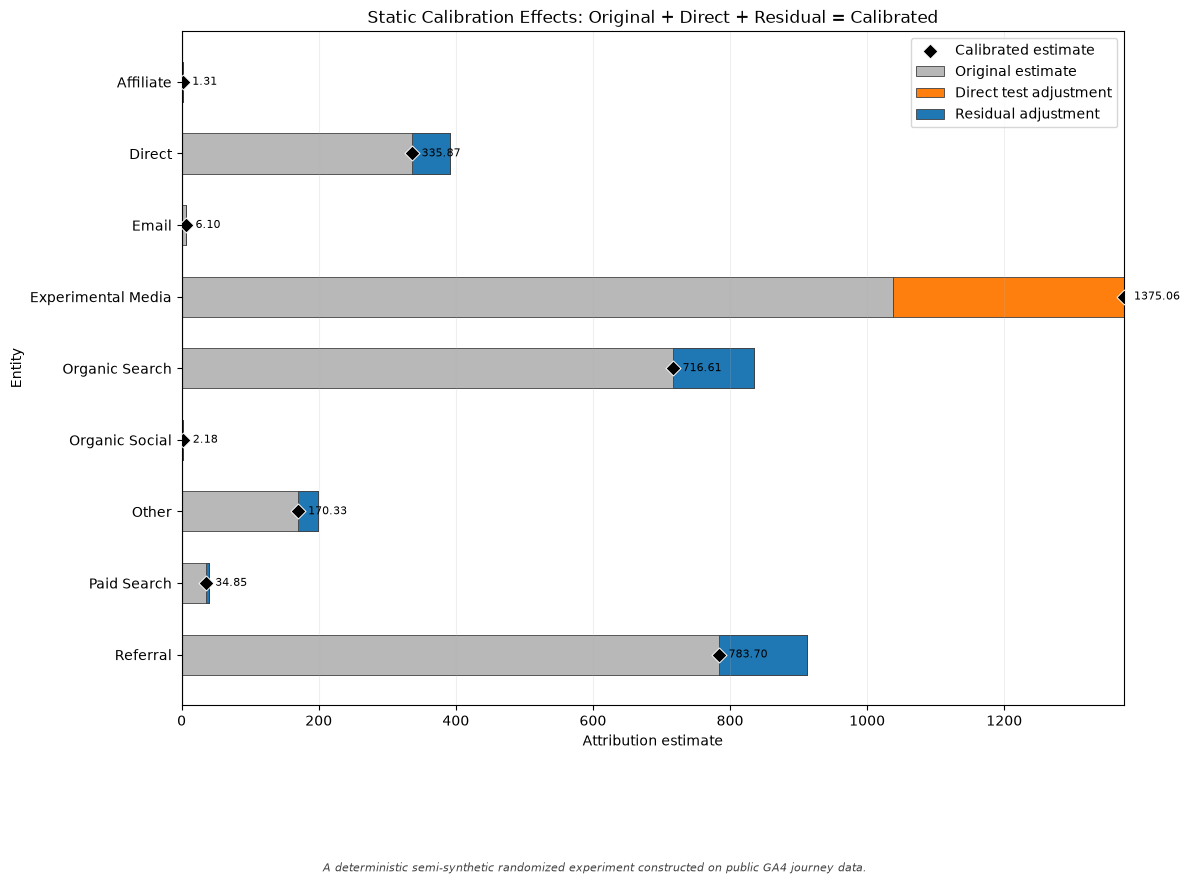

In [11]:
static_figure = label_figure(
    static_workflow.calibration_result.plot_calibration_effects()
)
plt.show()

## 11. Fit temporal attribution

`TemporalMarkovAttribution(freq="M")` fits the augmented journeys on the authoritative November, December, and January calendar epochs. Calibration consumes this grid unchanged. Separate static Markov fits on November and January provide the two exact window-matched MTA estimates.

In [12]:
temporal_workflow = fit_temporal_attribution_and_calibration(
    experiment_data,
    experimental_estimates=experimental_estimates,
    config=config,
)
display(temporal_workflow.attribution_model.get_epoch_summary())
display(pd.DataFrame(temporal_workflow.attribution_estimates_by_epoch).T)

,n_paths,n_conversions,n_channels,total_removal_effect,base_conversion_probability,effective_min_samples,sufficient_data,fit_ok,n_thin_channels
epoch,,,,,,,,,
2020-11,75229,2052,9,1.9211,0.0273,270,True,True,0
2020-12,102294,2115,8,1.5626,0.0207,240,True,True,0
2021-01,95269,1374,9,2.0466,0.0144,270,True,True,0


,Affiliate,Direct,Email,Experimental Media,Organic Search,Organic Social,Other,Paid Search,Referral
2020-11,1.0411,223.3151,5.7260,630.3836,511.1781,0.5205,121.2877,25.5068,533.0411
2020-12,0.6399,295.6520,10.8790,0.0000,737.8502,2.5598,198.3812,36.4766,832.5613
2021-01,0.4886,167.1081,1.4659,407.9979,323.9552,1.9545,77.2020,15.1472,378.6807


## 12. Estimate the two window-specific experiments

Each temporal evidence record uses its own randomized comparison and independently matched static Markov fit. The declared evidence coordinate is the corresponding monthly representative date; it is not inferred from the epoch label.

In [13]:
temporal_evidence_table = pd.DataFrame([
    {
        "test_id": evidence.test_id,
        "coordinate": evidence.coordinate_value,
        "observed_lift": evidence.observed_lift,
        "standard_error": evidence.standard_error,
        "matched_mta_estimate": evidence.matched_mta_estimate,
        "calibration_ratio": evidence.calibration_ratio,
        "true_expected_lift": evidence.metadata["true_expected_lift"],
        "declared_incremental_probability": evidence.metadata[
            "declared_incremental_probability"
        ],
        "experimental_layer": evidence.metadata["experimental_layer"],
    }
    for evidence in temporal_workflow.evidence
])
display(temporal_evidence_table)

,test_id,coordinate,observed_lift,standard_error,matched_mta_estimate,calibration_ratio,true_expected_lift,declared_incremental_probability,experimental_layer
0,experimental-media-ga4-2020-11,2020-11-16,776.7766,89.4607,630.3836,1.2322,883.3320,0.0120,A deterministic semi-synthetic randomized expe...
1,experimental-media-ga4-2021-01,2021-01-16,603.4618,73.6403,407.9979,1.4791,564.9240,0.0060,A deterministic semi-synthetic randomized expe...


## 13. Apply temporal calibration

The explicit policy chain is:

- `ratio_policy="coordinate_linear"`: construct a ratio schedule between the November and January evidence coordinates;
- `epoch_ratio_policy="representative_coordinate"`: reduce the schedule to one ratio at each declared monthly coordinate;
- `residual_policy="proportional_untested"`: preserve each epoch total through explicitly eligible untested recipients.

The December ratio is interpolated, not observed. Because `Experimental Media` has no December exposure or attribution estimate, that interpolated ratio creates no direct December adjustment.

In [14]:
temporal_tables = temporal_workflow.calibration_result.to_dataframes()
display(temporal_tables["epoch_ratios"])
display(temporal_tables["allocations"])
display(temporal_tables["totals"])
print(temporal_workflow.calibration_result.summary())

,tested_entity,epoch,epoch_start,epoch_end,epoch_coordinate,epoch_support,observed_ratio_count,effective_ratio,ratio_policy,epoch_ratio_policy,ratio_source,evidence_conflict_policy,source_evidence_ids,evidence_weights,left_source_evidence_id,right_source_evidence_id,ratio_bound_lower,ratio_bound_upper
0,Experimental Media,2020-11,2020-11-01,2020-12-01,2020-11-16,"75,229.0000",1,1.2322,coordinate_linear,representative_coordinate,observed,None,"(experimental-media-ga4-2020-11,)",None,NaN,NaN,None,None
1,Experimental Media,2020-12,2020-12-01,2021-01-01,2020-12-16,"102,294.0000",2,1.3536,coordinate_linear,representative_coordinate,interpolated,None,"(experimental-media-ga4-2020-11, experimental-...",None,experimental-media-ga4-2020-11,experimental-media-ga4-2021-01,None,None
2,Experimental Media,2021-01,2021-01-01,2021-02-01,2021-01-16,"95,269.0000",1,1.4791,coordinate_linear,representative_coordinate,observed,None,"(experimental-media-ga4-2021-01,)",None,NaN,NaN,None,None


,epoch,entity,original_estimate,direct_test_adjustment,residual_adjustment,net_adjustment,calibrated_estimate,original_share,calibrated_share,role
0,2020-11,Affiliate,1.0411,0.0000,-0.1072,-0.1072,0.9339,0.0005,0.0005,residual_recipient
1,2020-11,Direct,223.3151,0.0000,-22.9962,-22.9962,200.3189,0.1088,0.0976,residual_recipient
2,2020-11,Email,5.7260,0.0000,-0.5896,-0.5896,5.1364,0.0028,0.0025,residual_recipient
3,2020-11,Experimental Media,630.3836,146.3931,0.0000,146.3931,776.7766,0.3072,0.3785,tested
4,2020-11,Organic Search,511.1781,0.0000,-52.6393,-52.6393,458.5388,0.2491,0.2235,residual_recipient
5,2020-11,Organic Social,0.5205,0.0000,-0.0536,-0.0536,0.4669,0.0003,0.0002,residual_recipient
6,2020-11,Other,121.2877,0.0000,-12.4898,-12.4898,108.7979,0.0591,0.0530,residual_recipient
7,2020-11,Paid Search,25.5068,0.0000,-2.6266,-2.6266,22.8802,0.0124,0.0112,residual_recipient
8,2020-11,Referral,533.0411,0.0000,-54.8907,-54.8907,478.1504,0.2598,0.2330,residual_recipient
9,2020-12,Affiliate,0.6399,0.0000,0.0000,0.0000,0.6399,0.0003,0.0003,residual_recipient


,epoch,original_total,raw_post_test_total,required_residual,allocated_residual,calibrated_total,residual_policy
0,2020-11,"2,052.0000","2,198.3931",-146.3931,-146.3931,"2,052.0000",proportional_untested
1,2020-12,"2,115.0000","2,115.0000",0.0000,0.0000,"2,115.0000",proportional_untested
2,2021-01,"1,374.0000","1,569.4639",-195.4639,-195.4639,"1,374.0000",proportional_untested


Temporal Calibration Summary
Ratio policy: coordinate_linear
Epoch-ratio policy: representative_coordinate
Residual policy: proportional_untested

Authoritative temporal design
- Epoch 2020-11 was supplied by the attribution result.
  Boundary: 2020-11-01 to 2020-12-01.
  Boundary source: outcome-signal epoch design.
  Calibration did not modify the epoch.
- Epoch 2020-12 was supplied by the attribution result.
  Boundary: 2020-12-01 to 2021-01-01.
  Boundary source: outcome-signal epoch design.
  Calibration did not modify the epoch.
- Epoch 2021-01 was supplied by the attribution result.
  Boundary: 2021-01-01 to 2021-02-01.
  Boundary source: outcome-signal epoch design.
  Calibration did not modify the epoch.

Observed evidence
- Experimental Media evidence experimental-media-ga4-2020-11:
  coordinate date = 2020-11-16
  observed calibration ratio = 1.2322
  observed lift ± standard error = 776.78 ± 89.46 (standard error reported by the experiment; calibration does not use it)
  ma

## 14. Generate all seven temporal diagnostics

All seven figures below come from the same `TemporalCalibrationResult`. The evidence-strength diagnostic correctly says that explicit strength is not applicable to the selected coordinate-linear policy; its second panel compares the stored December representative-coordinate ratio with a nonapplied coordinate-average diagnostic. A second toy result is not substituted.

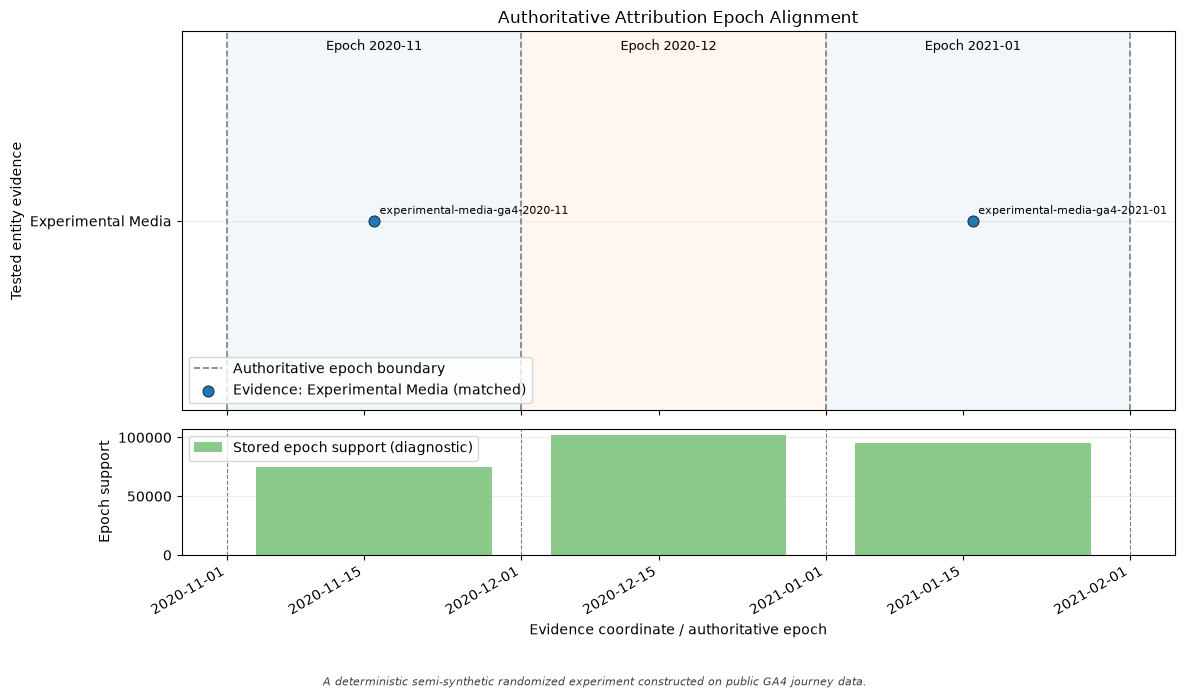

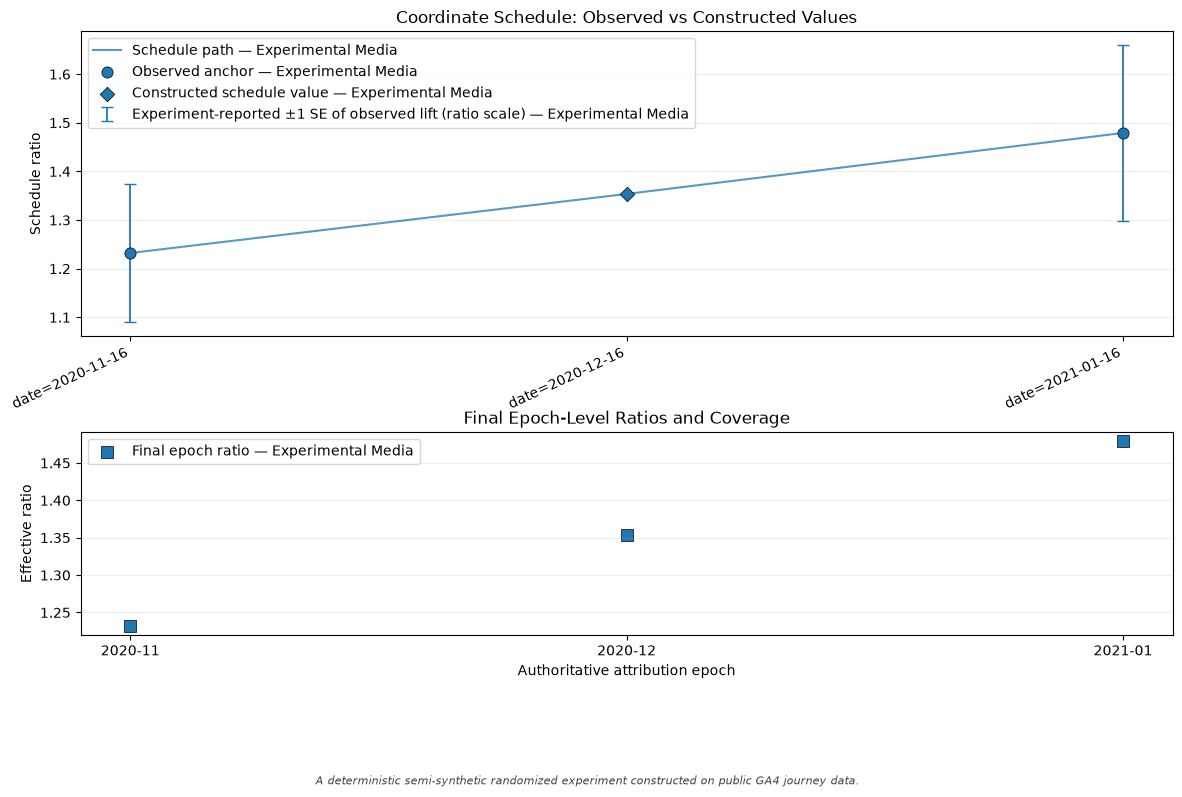

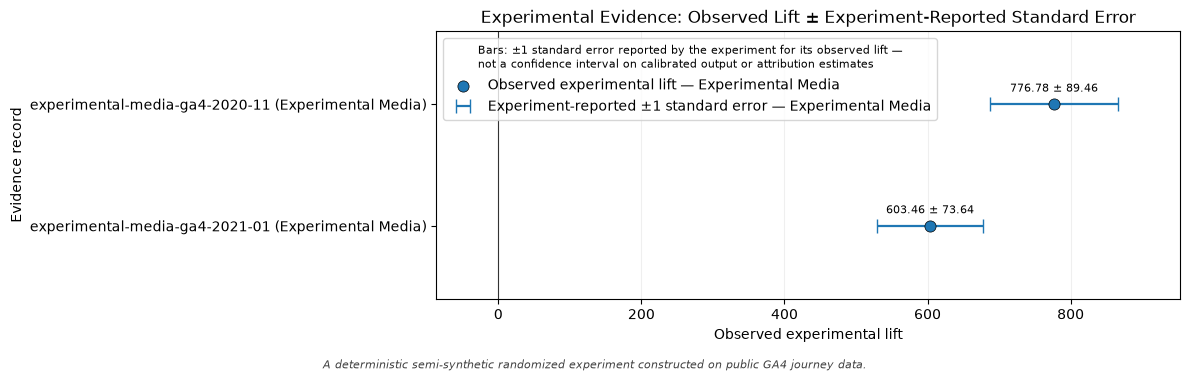

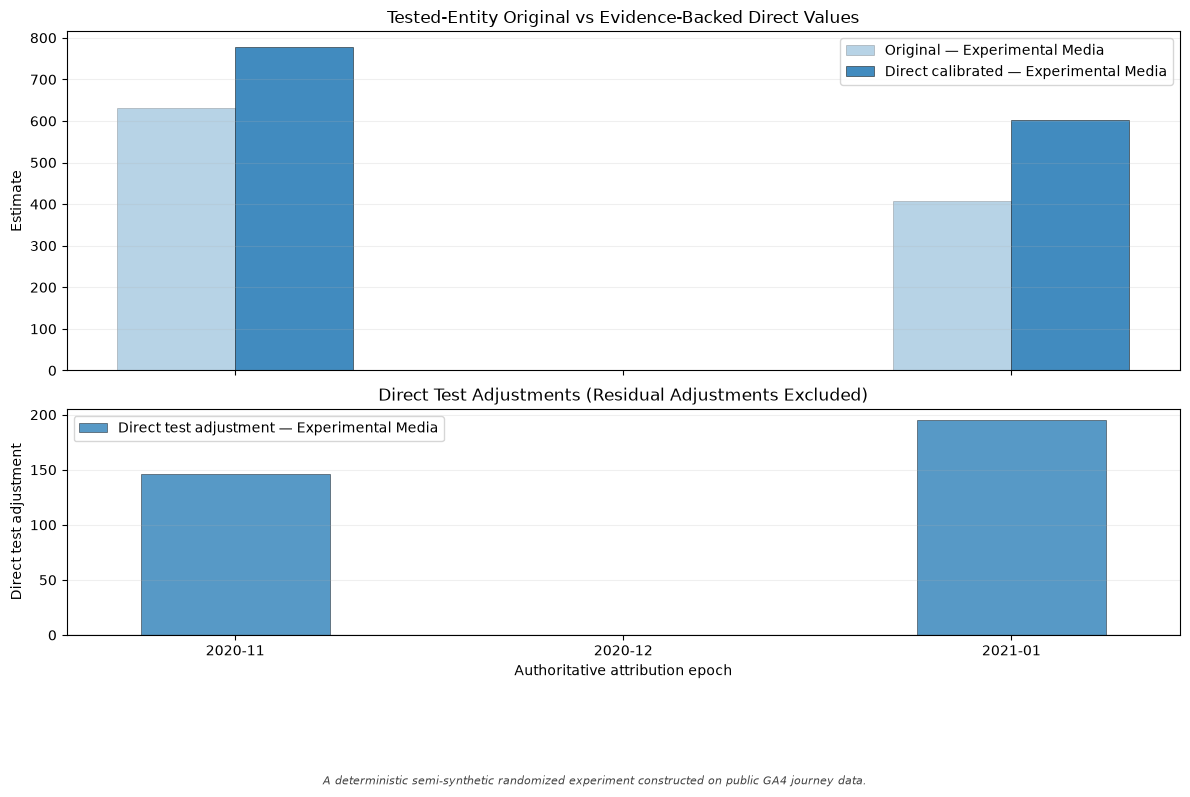

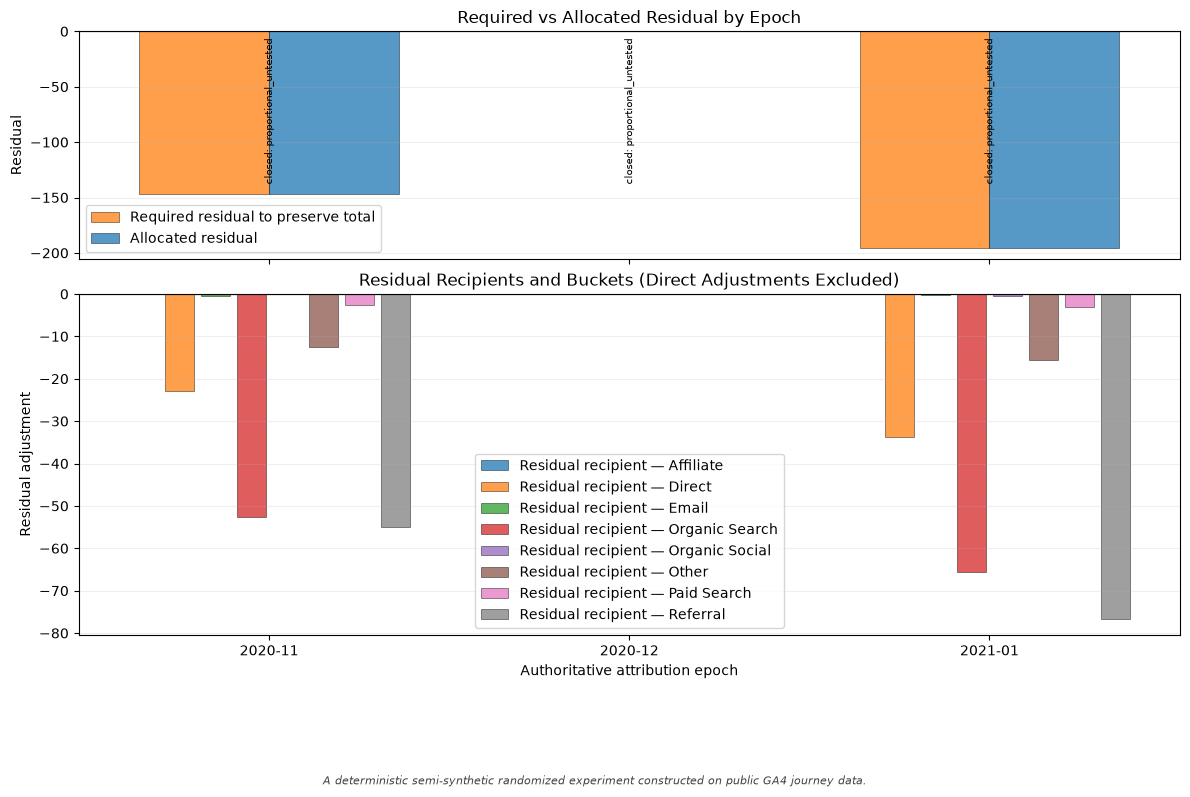

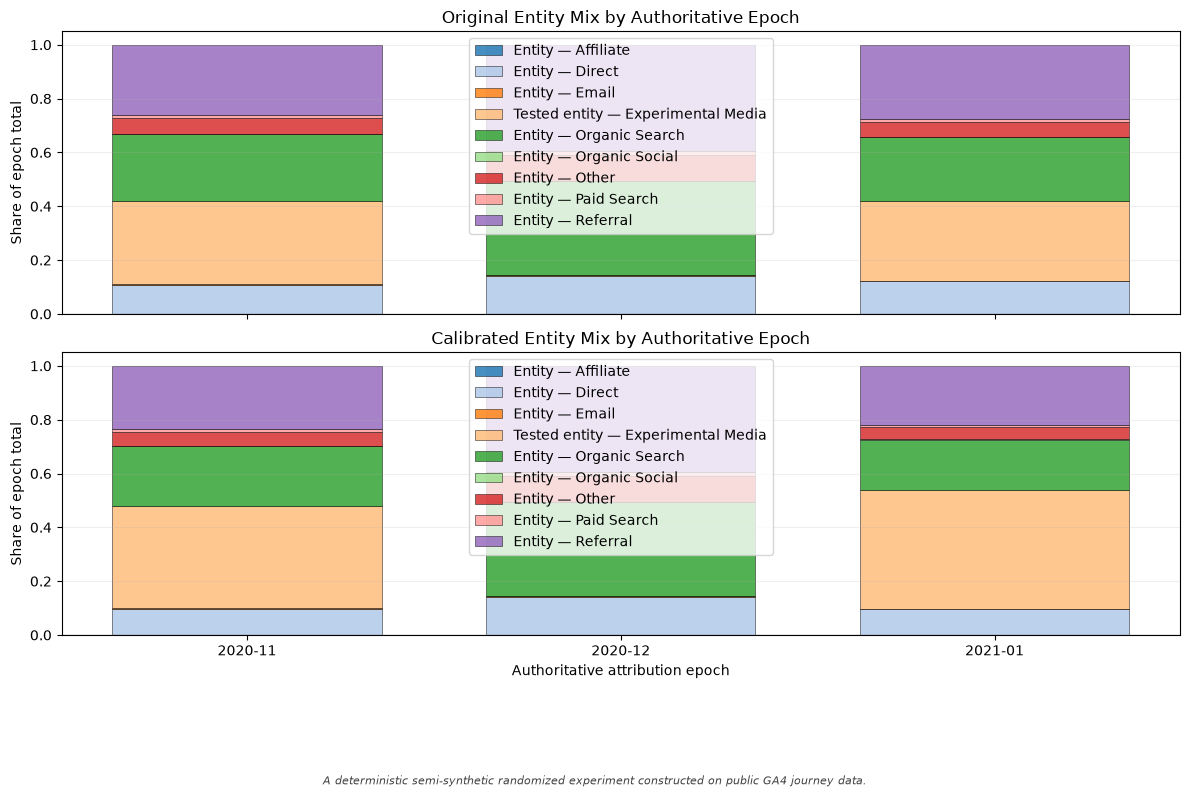

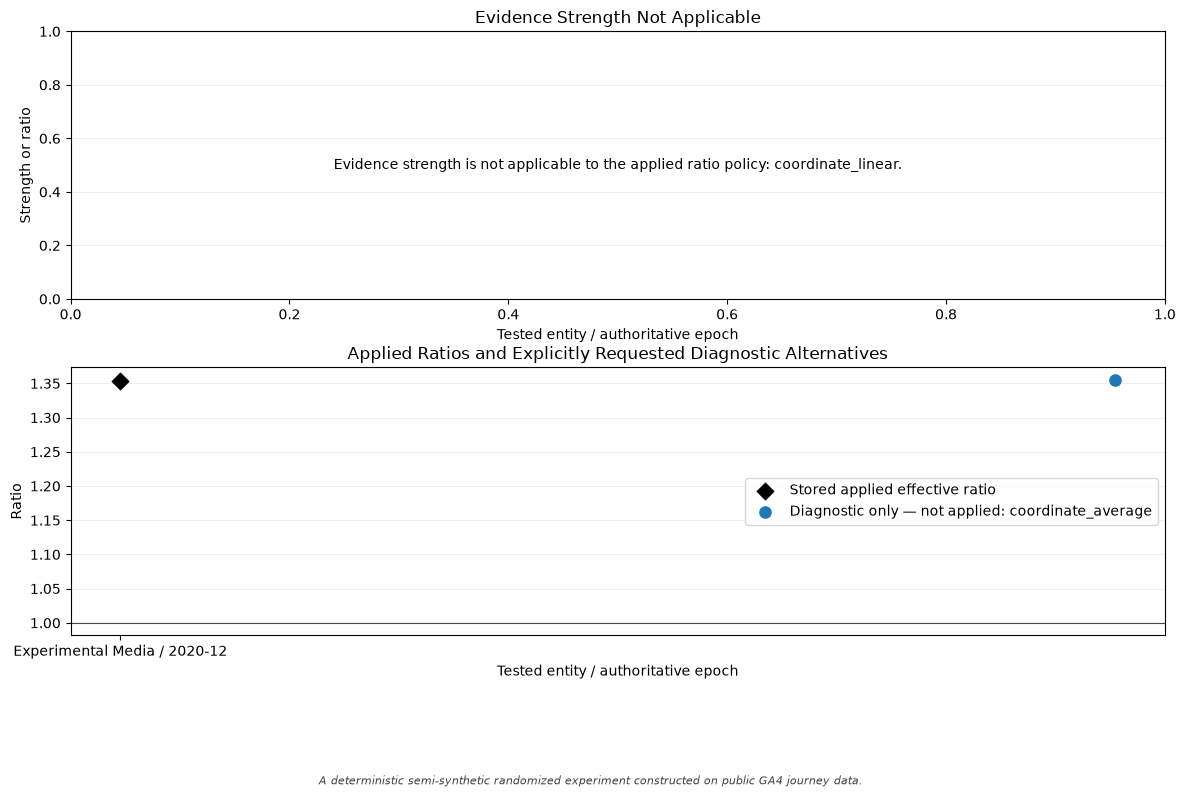

In [15]:
temporal_plot_methods = (
    "plot_epoch_alignment",
    "plot_ratio_schedule",
    "plot_evidence_uncertainty",
    "plot_calibration_effects",
    "plot_residual_allocation",
    "plot_entity_mix",
    "plot_evidence_strength",
)
middle_epoch = temporal_workflow.calibration_result.epochs[
    len(temporal_workflow.calibration_result.epochs) // 2
]
for method_name in temporal_plot_methods:
    plot_kwargs = {}
    if method_name == "plot_evidence_strength":
        plot_kwargs["diagnostic_epoch_ratio_policies"] = {
            (tested_entity, middle_epoch): ("coordinate_average",)
        }
    figure = label_figure(
        getattr(temporal_workflow.calibration_result, method_name)(**plot_kwargs)
    )
    plt.show()

## Checks

These compact assertions reconcile the source, experiment, evidence, and calibration layers before interpretation.

In [16]:
assert journeys["journey_id"].nunique() == len(journeys)
assert set(journeys["conversion"].unique()) <= {0, 1}
assert (
    experiment_data["observed_conversion"].to_numpy()
    == np.maximum(
        experiment_data["baseline_conversion"].to_numpy(),
        experiment_data["incremental_conversion"].to_numpy(),
    )
).all()
assert experiment_data.loc[
    experiment_data["incremental_conversion"].eq(1), "campaign_assigned"
].all()
assert static_evidence.matched_mta_estimate == static_workflow.attribution_estimates[
    tested_entity
]
assert [row.ratio_source for row in temporal_workflow.calibration_result.epoch_ratio_schedule] == [
    "observed", "interpolated", "observed"
]
for epoch in temporal_workflow.calibration_result.epochs:
    assert np.isclose(
        temporal_workflow.calibration_result.original_totals[epoch],
        temporal_workflow.calibration_result.calibrated_totals[epoch],
    )
print("All source, randomization, matching, and conservation checks passed.")

All source, randomization, matching, and conservation checks passed.


## 15. Compare uncalibrated attribution, experimental lift, and calibrated attribution

For the tested entity, direct calibration makes the calibrated attribution equal the matched randomized lift by construction. The standard error and known simulation estimand remain visible so the point estimate is not mistaken for exact truth.

In [17]:
comparison = calibration_comparison_table(
    static_workflow,
    temporal_workflow,
    experimental_estimates,
    config=config,
)
display(comparison)

,scope,experimental_lift,experimental_standard_error,true_expected_lift,matched_mta_estimate,calibration_ratio,calibrated_attribution
0,Static: all eligible windows,"1,375.0555",115.9800,"1,448.2560","1,037.8436",1.3249,"1,375.0555"
1,Temporal: November 2020,776.7766,89.4607,883.3320,630.3836,1.2322,776.7766
2,Temporal: January 2021,603.4618,73.6403,564.9240,407.9979,1.4791,603.4618


## 16. State interpretation limits

- **Semi-synthetic, not a Google experiment.** GA4 supplies public obfuscated journey structures and baseline outcomes; this notebook supplies assignment, campaign exposure, and incremental outcomes.
- **Randomized lift is causal only for this constructed assignment and estimand.** It does not establish a real-media effect or transport to another advertiser, campaign, population, or period.
- **Markov attribution remains an associational decomposition.** Calibration aligns the tested entity to experimental evidence; it does not turn untested-channel attribution into causal effects.
- **Residual recipients were not tested.** Their changes are consequences of the declared total-preserving allocation policy.
- **December interpolation is a policy choice, not evidence.** The campaign is absent in December, so the interpolated ratio has no direct effect here. Other datasets could produce a consequential interpolation, which would require substantive justification.
- **One simulated draw has sampling noise.** Compare the randomized point estimate and interval with `true_expected_lift`; neither is expected to match exactly in one realization.
- **No unrelated uplift dataset or external lift number is combined with GA4.** Every calibration numerator and denominator is calculated on these same journey rows.

## Next Steps

Change the fixed seed or declared incremental probabilities only as an explicit sensitivity analysis, then rerun top to bottom. For a real deployment, replace the synthetic assignment/outcome layer with experiment records that can be matched to the attribution population, outcome, entity, and window under the same contract.